In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Electronics_Sales_Dirty_Dataset_200.pdf to Electronics_Sales_Dirty_Dataset_200.pdf
Saving IMG-20261008-WA0085.jpg to IMG-20261008-WA0085.jpg


In [ ]:
!pip install pypdf
from pypdf import PdfReader
# PDF load karein
reader = PdfReader('Electronics_Sales_Dirty_Dataset_200.pdf')
# Pehle page ka text dekhein
print(reader.pages[0].extract_text())

RAW / DIRTY DATASET FOR CLEANING ANALYSIS (200 RECORDS)
Contains intentional data quality issues: Missing Values, Typos, Wrong Calculations & Outliers
Page 1
Electronics Sales Analysis — Uncleaned Raw Dataset (Dirty Data)
Dataset designed for Data Cleaning, Missing Value Imputation & Quality Assurance Practice
Note for Analysts: This dataset intentionally contains missing values ('N/A', 'UNKNOWN', 'NULL'), city name typos ('Mumbay', 'BLR', 'Delhy'), inconsistent payment tags ('U.P.I.', 'cc', 'FAILED_TXN'), calculation
errors (Qty × Unit Price ≠ Total), and price outliers.
 Invoice ID
 Date
 City Branch
 Product Category
 Product Name
 Qty
 Unit Price
 Total Amount
 Payment Method
 Rating
 INV-2024-1001
 2024-02-02
Delhi
Mobile Accessories
Portable Power Bank 10000mAh
 4
 ₹1,299
 ₹5,196
Net Banking
 3.1
 INV-2024-1002
 2024-03-03
Mumbai
Wearables
Fitness Smart Band
 2
 ₹2,499
 ₹4,998
Net Banking
 3.3
 INV-2024-1003
 2024-01-04
Delhi
Audio & Sound
TWS Wireless Earbuds
 4
 ₹2,999
 ₹11,996

In [ ]:
!pip install pdfplumber pandas

import pdfplumber
import pandas as pd

# 1. PDF se tables extract karke DataFrame banayein
data = []
with pdfplumber.open('Electronics_Sales_Dirty_Dataset_200.pdf') as pdf:
 for page in pdf.pages:
  table = page.extract_table()
  if table: data.extend(table)

# Pehli row ko column headers banayein
df = pd.DataFrame(data[1:], columns=data[0])

# 2. Automatic Data Cleaning
# A. Unwanted spaces (leading/trailing whitespace) hatayein
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# B. Duplicate rows hatayein
df = df.drop_duplicates()

# C. Missing values ko default values se replace karein
df = df.fillna('Unknown')

# 3. Cleaned Dataset dekhein aur Excel/CSV me save karein
print("Cleaned Data Shape:", df.shape)
df.to_csv('Cleaned_Electronics_Sales.csv', index=False)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 106.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 119.3 MB/s eta 0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
Cleaned Data Shape: (201, 10)


In [ ]:
!pip install pdfplumber pandas reportlab
import pdfplumber
import pandas as pd
from reportlab.lib.pagesizes import A4, landscape
from reportlab.platypus import SimpleDocTemplate, Table, TableStyle, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors

# 1. Uploaded PDF se data extract karke DataFrame banayein
data = []
with pdfplumber.open('Electronics_Sales_Dirty_Dataset_200.pdf') as pdf:
   for page in pdf.pages:
      table = page.extract_table()
      if table:
       data.extend(table)
       df = pd.DataFrame(data[1:], columns=data[0])

# 2. Data Cleaning (Errors, Missing Values, City &amp; Payments)
# A. Leading/Trailing extra spaces saaf karein
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# B. City / Location Name ki spelling mistakes thik karein (Proper Title Case)
for col in ['City', 'Location', 'Store_Location']:
  if col in df.columns:
    df[col] = df[col].str.title()

 # C. Payment Label Variations &amp; Fraud Status standard karein
  for col in ['Payment', 'Payment_Method', 'Status']:
    if col in df.columns: df[col] = df[col].str.upper()

# D. Missing values ko default label 'N/A' se fill karein
df = df.fillna('N/A')

# E. Duplicate rows hatayein
df = df.drop_duplicates()

# 3. Cleaned Data ki PDF File Banayein
pdf_filename = "Cleaned_Electronics_Sales_Dataset.pdf"
doc = SimpleDocTemplate(pdf_filename, pagesize=landscape(A4))
elements = []

styles = getSampleStyleSheet()
elements.append(Paragraph("<b>Cleaned Electronics Sales Dataset Report</b>",styles['Title']))

 # Table Formatting
table_data = [df.columns.tolist()] + df.values.tolist()
t = Table(table_data)
t.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.navy),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.whitesmoke),
    ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
    ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
    ('FONTSIZE', (0, 0), (-1, -1), 8),
    ('BOTTOMPADDING', (0, 0), (-1, 0), 6),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.grey), ]))

elements.append(t)
doc.build(elements)


print(f"Cleaning complete! Final PDF file saved as:{pdf_filename}")

Cleaning complete! Final PDF file saved as:Cleaned_Electronics_Sales_Dataset.pdf


In [ ]:
import pandas as pd
# Cleaned CSV file load karein df = pd.read_csv('Cleaned_Electronics_Sales.csv')

# Numeric columns ko numeric format me convert karein
df['Total Amount'] = pd.to_numeric(df['Total Amount'].astype(str).str.replace('₹', '').str.replace(',', ''), errors='coerce')
df['Qty'] = pd.to_numeric(df['Qty'], errors='coerce')
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# 1. Overall Key Summary Metrics print("===== 📊 OVERALL DATASET SUMMARY =====")
print(f"Total Transactions: {len(df)}")
print(f"Total Revenue (Sales): ₹{df['Total Amount'].sum():,.2f}")
print(f"Total Quantity Sold: {df['Qty'].sum():,.0f}")
print(f"Average Customer Rating: {df['Rating'].mean():.2f} / 5.0")

# 2. City / Branch Performance Summary
print("\n===== 🏢 CITY-WISE SALES SUMMARY =====")
city_col = 'City Branch' if 'City Branch' in df.columns else 'City'
city_summary = df.groupby(city_col)['Total Amount'].sum().reset_index()
print(city_summary.sort_values(by='Total Amount', ascending=False).to_string(index=False))

# 3. Top Selling Product Categories
print("\n===== 📦 CATEGORY-WISE SALES SUMMARY =====")
category_summary = df.groupby('Product Category')['Total Amount'].sum().reset_index()
print(category_summary.sort_values(by='Total Amount', ascending=False).to_string(index=False))

# 4. Payment Method Summary print("\n===== 💳 PAYMENT METHOD SUMMARY =====")
payment_summary = df['Payment Method'].value_counts().reset_index()
payment_summary.columns = ['Payment Method', 'Count']
print(payment_summary.to_string(index=False))

Total Transactions: 201
Total Revenue (Sales): ₹11,226,747.00
Total Quantity Sold: 929
Average Customer Rating: 3.94 / 5.0

===== 🏢 CITY-WISE SALES SUMMARY =====
 City Branch  Total Amount
   Bengaluru     6437877.0
      Mumbai     3483509.0
     Kolkata      373197.0
       Delhi      347214.0
     Chennai      242928.0
         N/A      132357.0
   bengaluru       75996.0
   Bangalore       46996.0
         BLR       25693.0
       Delhy       22996.0
    Calcutta       22495.0
MUMBAI_STORE       10194.0
      Mumbay        5295.0
 City Branch           0.0

===== 📦 CATEGORY-WISE SALES SUMMARY =====
     Product Category  Total Amount
            Wearables     4282217.0
        Audio & Sound     3392901.0
   MOBILE ACCESSORIES     1999998.0
 Computer Accessories      545428.0
Smartphones & Tablets      493974.0
           Smart Home      221736.0
 Personal Electronics      106344.0
   Mobile Accessories       99672.0
 COMPUTER ACCESSORIES       19998.0
           smart home       16

/tmp/ipykernel_1486/3012497313.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_sales, x=city_col, y='Total Amount', ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_1486/3012497313.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_sales, x='Product Category', y='Total Amount', ax=axes[0, 1], palette='Greens_r')
/tmp/ipykernel_1486/3012497313.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_qty, x='Product Category', y='Qty', ax=axes[1, 1], palette='Oranges_r')


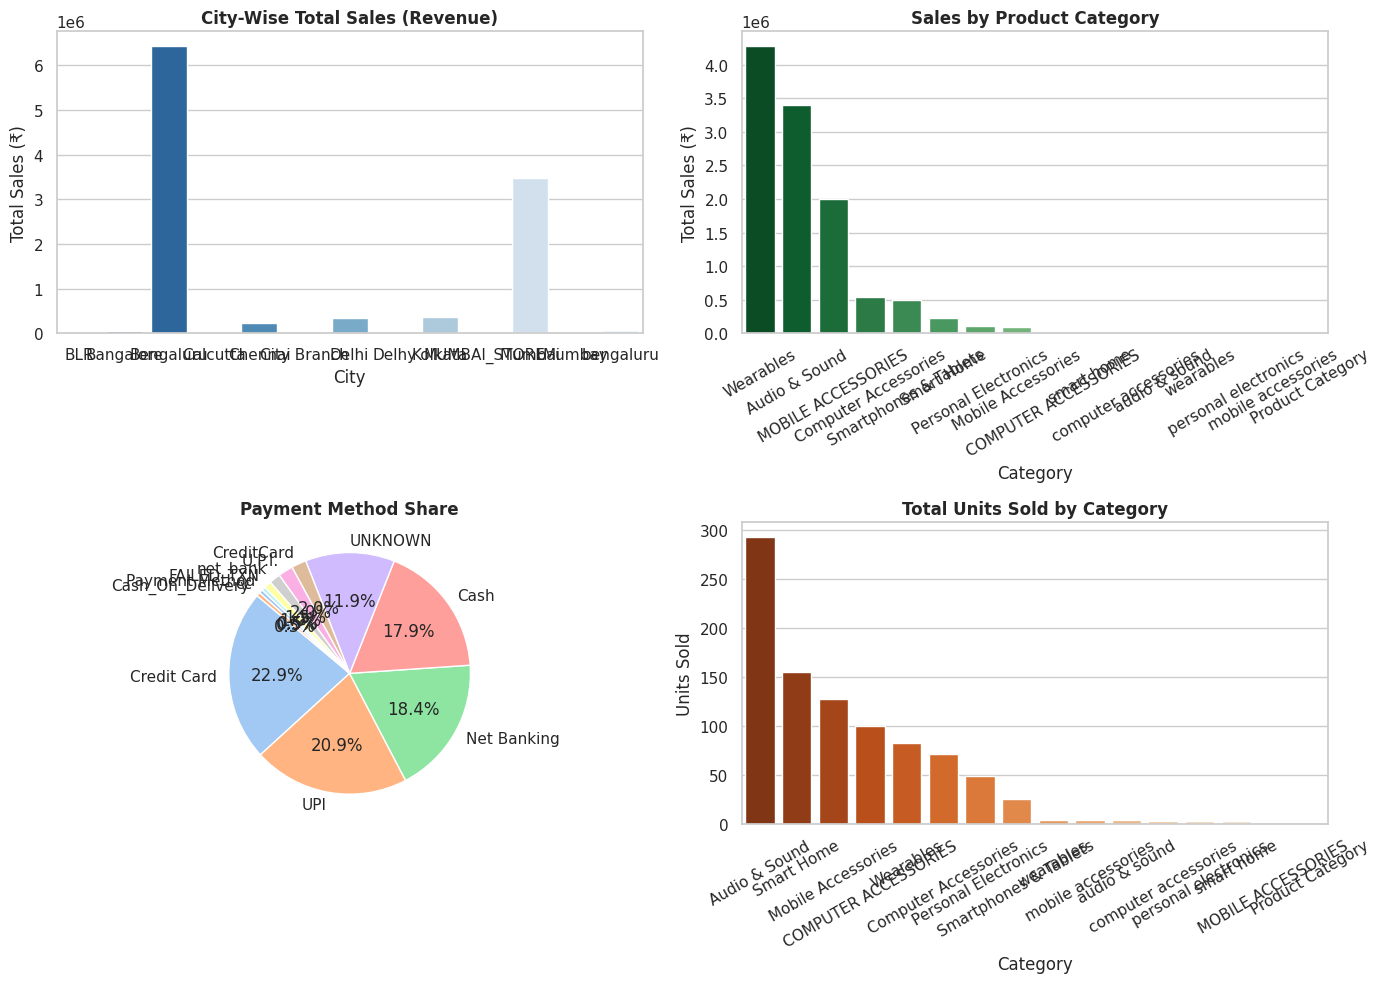

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cleaned CSV file load karein
df = pd.read_csv('Cleaned_Electronics_Sales.csv')

# Numeric columns convert karein
df['Total Amount'] = pd.to_numeric(df['Total Amount'].astype(str).str.replace('₹', '').str.replace(',', ''), errors='coerce')
df['Qty'] = pd.to_numeric(df['Qty'], errors='coerce')

# Visual style set karein
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar Chart: City-Wise Total Sales
city_col = 'City Branch' if 'City Branch' in df.columns else 'City'
city_sales = df.groupby(city_col)['Total Amount'].sum().reset_index()
sns.barplot(data=city_sales, x=city_col, y='Total Amount', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('City-Wise Total Sales (Revenue)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('City')
axes[0, 0].set_ylabel('Total Sales (₹)')

# 2. Bar Chart: Category-Wise Sales
cat_sales = df.groupby('Product Category')['Total Amount'].sum().reset_index().sort_values(by='Total Amount', ascending=False)
sns.barplot(data=cat_sales, x='Product Category', y='Total Amount', ax=axes[0, 1], palette='Greens_r')
axes[0, 1].set_title('Sales by Product Category', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Category')
axes[0, 1].set_ylabel('Total Sales (₹)')
axes[0, 1].tick_params(axis='x', rotation=30)

# 3. Pie Chart: Payment Method Distribution
payment_counts = df['Payment Method'].value_counts()
axes[1, 0].pie(payment_counts,labels=payment_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[1, 0].set_title('Payment Method Share', fontsize=12, fontweight='bold')

# 4. Bar Chart: Total Quantity Sold by Category
cat_qty = df.groupby('Product Category')['Qty'].sum().reset_index().sort_values(by='Qty', ascending=False)
sns.barplot(data=cat_qty, x='Product Category', y='Qty', ax=axes[1, 1], palette='Oranges_r')
axes[1, 1].set_title('Total Units Sold by Category', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Category')
axes[1, 1].set_ylabel('Units Sold')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()